# Imports, Dataset Integrity Check (SHA256), and Raw Load

In [18]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths
BASE_DIR = Path("..")
DATA_PATH = BASE_DIR / "data" / "Online Retail.xlsx"
REPORTS_DIR = BASE_DIR / "reports"
FIGURES_DIR = BASE_DIR / "figures"
MODELS_DIR = BASE_DIR / "models"

for d in [REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 1. Verify SHA256 hash of untouched raw file
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"Dataset SHA256: {sha256}")

# 2. Load raw dataset (keep InvoiceNo and CustomerID as strings where possible)
raw_df = pd.read_excel(DATA_PATH, dtype={"InvoiceNo": str, "StockCode": str})
print(f"Raw shape: {raw_df.shape}")
display(raw_df.head(3))
print("\nData types:\n", raw_df.dtypes)

Dataset SHA256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom



Data types:
 InvoiceNo                 str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


# Full Data Audit & Reconciled Exclusion Table

In [19]:
df = raw_df.copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["LineValue"] = df["Quantity"] * df["UnitPrice"]
df = df.sort_values("InvoiceDate").reset_index(drop=True)

audit_rows = []
def log_stage(stage_name, current_df, excluded_df=None):
    audit_rows.append({
        "Stage": stage_name,
        "Remaining_Rows": len(current_df),
        "Remaining_Gross_GBP": round(current_df["LineValue"].sum(), 2),
        "Excluded_Rows_This_Step": 0 if excluded_df is None else len(excluded_df),
        "Excluded_GBP_This_Step": 0.0 if excluded_df is None else round(excluded_df["LineValue"].sum(), 2),
    })

log_stage("0. Raw Dataset Loaded", df)

# Rule 1: Filter strictly to United Kingdom
non_uk = df[df["Country"] != "United Kingdom"]
df = df[df["Country"] == "United Kingdom"].copy()
log_stage("1. Filter Country == 'United Kingdom'", df, non_uk)

# Rule 2: Missing CustomerID (cannot link to a customer)
missing_cid = df[df["CustomerID"].isna()]
df = df[df["CustomerID"].notna()].copy()
df["CustomerID"] = df["CustomerID"].astype(float).astype(int).astype(str)
log_stage("2. Remove Missing CustomerID", df, missing_cid)

# Rule 3: Exact duplicate rows
exact_dups = df[df.duplicated(keep="first")]
df = df.drop_duplicates(keep="first").copy()
log_stage("3. Remove Exact Duplicate Rows", df, exact_dups)

# Rule 4: Cancelled invoices (InvoiceNo starting with 'C')
cancelled = df[df["InvoiceNo"].str.startswith("C", na=False)]
df = df[~df["InvoiceNo"].str.startswith("C", na=False)].copy()
log_stage("4. Exclude Cancelled Invoices ('C*')", df, cancelled)

# Rule 5: Zero or negative Quantity or UnitPrice
non_pos = df[(df["Quantity"] <= 0) | (df["UnitPrice"] <= 0)]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
log_stage("5. Exclude Quantity <= 0 or UnitPrice <= 0", df, non_pos)

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(REPORTS_DIR / "audit.csv", index=False)
display(audit_df)

# Save separate audit record of UK cancellations/returns as required
uk_cancellations = raw_df[
    (raw_df["Country"] == "United Kingdom") & 
    (raw_df["InvoiceNo"].astype(str).str.startswith("C") | (raw_df["Quantity"] < 0))
].copy()
uk_cancellations["LineValue"] = uk_cancellations["Quantity"] * uk_cancellations["UnitPrice"]
uk_cancellations.to_csv(REPORTS_DIR / "uk_cancellations_audit.csv", index=False)
print(f"Saved UK cancellations/returns audit: {len(uk_cancellations)} rows, total GBP: {uk_cancellations['LineValue'].sum():,.2f}")

,Stage,Remaining_Rows,Remaining_Gross_GBP,Excluded_Rows_This_Step,Excluded_GBP_This_Step
0,0. Raw Dataset Loaded,541909,9747747.93,0,0.00
1,1. Filter Country == 'United Kingdom',495478,8187806.36,46431,1559941.57
2,2. Remove Missing CustomerID,361878,6767873.39,133600,1419932.97
3,3. Remove Exact Duplicate Rows,356728,6747156.15,5150,20717.24
4,4. Exclude Cancelled Invoices ('C*'),349227,7285024.64,7501,-537868.49
5,5. Exclude Quantity <= 0 or UnitPrice <= 0,349203,7285024.64,24,0.00


Saved UK cancellations/returns audit: 9192 rows, total GBP: -815,291.60


# Reusable RFM Feature Builder + Strict Assertions

In [20]:
def build_rfm_features(clean_txns: pd.DataFrame, cutoff_str: str) -> pd.DataFrame:
    """
    Build customer-level RFM features using ONLY valid positive UK transactions
    dated strictly before cutoff_str (midnight at the start of that date).
    """
    cutoff_dt = pd.Timestamp(cutoff_str)
    
    # Filter strictly before cutoff timestamp
    eligible_txns = clean_txns[clean_txns["InvoiceDate"] < cutoff_dt].copy()
    
    # Guardrail assertion: no transaction at or after cutoff
    assert (eligible_txns["InvoiceDate"] < cutoff_dt).all(), "Leakage detected: transactions >= cutoff!"
    
    # Aggregate per CustomerID
    rfm = (
        eligible_txns.groupby("CustomerID", as_index=False)
        .agg(
            LastPurchaseDate=("InvoiceDate", "max"),
            Frequency=("InvoiceNo", "nunique"),
            Monetary=("LineValue", "sum"),
        )
    )
    
    # Recency in whole days since latest purchase relative to cutoff midnight
    # Note: Using calendar day difference (cutoff_dt.normalize() - LastPurchaseDate.dt.normalize()).dt.days
    # matches the brief's example (20 July to 1 August = 12 days).
    rfm["Recency"] = (cutoff_dt.normalize() - rfm["LastPurchaseDate"].dt.normalize()).dt.days
    
    # Keep required columns in clean order
    rfm = rfm[["CustomerID", "Recency", "Frequency", "Monetary"]].sort_values("CustomerID").reset_index(drop=True)
    
    # Required Part B assertions
    assert rfm["CustomerID"].is_unique, "Duplicate CustomerID rows found in RFM table!"
    assert np.isfinite(rfm[["Recency", "Frequency", "Monetary"]].values).all(), "Non-finite RFM values found!"
    assert (rfm["Recency"] >= 0).all(), "Negative Recency found!"
    assert (rfm["Frequency"] >= 1).all(), "Frequency < 1 found!"
    assert (rfm["Monetary"] > 0).all(), "Non-positive Monetary found!"
    
    return rfm

# Build RFM tables for both required cutoffs
rfm_dev = build_rfm_features(df, "2011-08-01")     # Development cutoff
rfm_final = build_rfm_features(df, "2011-09-01")   # Final assessment cutoff

rfm_dev.to_csv(REPORTS_DIR / "rfm_dev_2011_08_01.csv", index=False)
rfm_final.to_csv(REPORTS_DIR / "rfm_final_2011_09_01.csv", index=False)

print(f"Development (before 2011-08-01): N = {len(rfm_dev)} eligible UK customers, B = {min(200, int(np.floor(0.10 * len(rfm_dev))))}")
print(f"Final (before 2011-09-01):       N = {len(rfm_final)} eligible UK customers, B = {min(200, int(np.floor(0.10 * len(rfm_final))))}")
display(rfm_dev.describe())

Development (before 2011-08-01): N = 2848 eligible UK customers, B = 200
Final (before 2011-09-01):       N = 2989 eligible UK customers, B = 200


,Recency,Frequency,Monetary
count,2848.000000,2848.000000,2848.000000
mean,81.965239,3.212079,1307.994980
std,68.400178,4.961244,4343.075521
min,1.000000,1.000000,2.900000
25%,25.000000,1.000000,241.530000
50%,62.000000,2.000000,494.830000
75%,126.250000,3.000000,1140.572500
max,243.000000,115.000000,129551.310000


# Skewness & Extreme Value Summary Plots

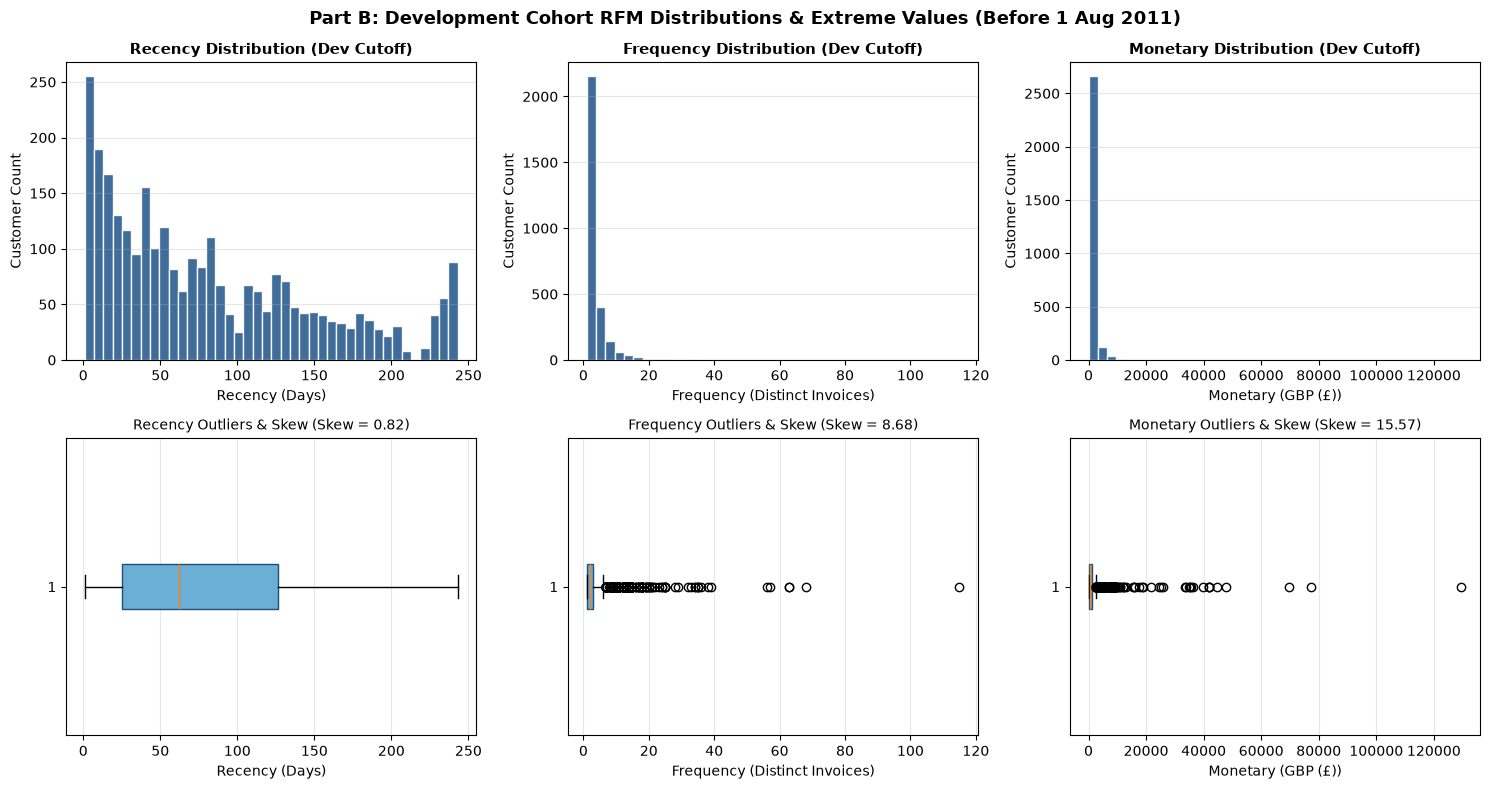

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
features = ["Recency", "Frequency", "Monetary"]
units = ["Days", "Distinct Invoices", "GBP (£)"]

for idx, (feat, unit) in enumerate(zip(features, units)):
    # Top row: Histograms showing right-skewness
    axes[0, idx].hist(rfm_dev[feat], bins=40, color="#2b5c8f", edgecolor="white", alpha=0.9)
    axes[0, idx].set_title(f"{feat} Distribution (Dev Cutoff)", fontsize=11, fontweight="bold")
    axes[0, idx].set_xlabel(f"{feat} ({unit})")
    axes[0, idx].set_ylabel("Customer Count")
    axes[0, idx].grid(axis="y", alpha=0.3)
    
    # Bottom row: Boxplots highlighting extreme outliers
    axes[1, idx].boxplot(rfm_dev[feat], orientation="horizontal", patch_artist=True,
                         boxprops=dict(facecolor="#6baed6", color="#1f4e78"))
    axes[1, idx].set_title(f"{feat} Outliers & Skew (Skew = {rfm_dev[feat].skew():.2f})", fontsize=10)
    axes[1, idx].set_xlabel(f"{feat} ({unit})")
    axes[1, idx].grid(axis="x", alpha=0.3)

plt.suptitle("Part B: Development Cohort RFM Distributions & Extreme Values (Before 1 Aug 2011)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part_b_rfm_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

# Two Manual Customer Checks (Including One With Cancellations)

In [22]:
cutoff_check = pd.Timestamp("2011-08-01")
uk_raw_pre = raw_df[(raw_df["Country"] == "United Kingdom") & (raw_df["CustomerID"].notna())].copy()
uk_raw_pre["InvoiceDate"] = pd.to_datetime(uk_raw_pre["InvoiceDate"])
uk_raw_pre["CustomerID"] = uk_raw_pre["CustomerID"].astype(float).astype(int).astype(str)
uk_raw_pre = uk_raw_pre[uk_raw_pre["InvoiceDate"] < cutoff_check].copy()
uk_raw_pre["LineValue"] = uk_raw_pre["Quantity"] * uk_raw_pre["UnitPrice"]

# Customer 1: Has at least one cancellation ('C*') AND at least one valid positive purchase before cutoff
cids_with_cancel = set(uk_raw_pre[uk_raw_pre["InvoiceNo"].str.startswith("C", na=False)]["CustomerID"])
cids_valid = set(rfm_dev["CustomerID"])
both_cids = sorted(list(cids_with_cancel.intersection(cids_valid)))

# Pick a customer with a small, easily readable transaction history (between 3 and 12 total rows)
cid_cancel_sample = next(
    cid for cid in both_cids if 3 <= len(uk_raw_pre[uk_raw_pre["CustomerID"] == cid]) <= 12
)

# Customer 2: Clean customer with no cancellations and 2-5 rows
clean_only_cids = sorted(list(cids_valid - cids_with_cancel))
cid_clean_sample = next(
    cid for cid in clean_only_cids if 2 <= len(uk_raw_pre[uk_raw_pre["CustomerID"] == cid]) <= 6
)

for label, cid in [("Manual Check 1 (Customer WITH Cancellation)", cid_cancel_sample),
                   ("Manual Check 2 (Clean Customer WITHOUT Cancellation)", cid_clean_sample)]:
    print("=" * 75)
    print(f"{label} — CustomerID: {cid}")
    cust_txns = uk_raw_pre[uk_raw_pre["CustomerID"] == cid].sort_values("InvoiceDate")
    display(cust_txns[["InvoiceNo", "InvoiceDate", "StockCode", "Quantity", "UnitPrice", "LineValue"]])
    
    # Independent manual calculation from raw UK lines
    valid_lines = cust_txns[(~cust_txns["InvoiceNo"].str.startswith("C", na=False)) & 
                            (cust_txns["Quantity"] > 0) & (cust_txns["UnitPrice"] > 0)]
    manual_recency = (cutoff_check.normalize() - valid_lines["InvoiceDate"].max().normalize()).days
    manual_freq = valid_lines["InvoiceNo"].nunique()
    manual_monetary = round(valid_lines["LineValue"].sum(), 4)
    
    func_row = rfm_dev[rfm_dev["CustomerID"] == cid].iloc[0]
    print(f"Manual Calc   -> Recency: {manual_recency} days | Frequency: {manual_freq} | Monetary: £{manual_monetary:.2f}")
    print(f"Function Out  -> Recency: {func_row['Recency']} days | Frequency: {func_row['Frequency']} | Monetary: £{func_row['Monetary']:.2f}")
    
    assert manual_recency == func_row["Recency"]
    assert manual_freq == func_row["Frequency"]
    assert np.isclose(manual_monetary, func_row["Monetary"])
    print("STATUS: EXACT MATCH VERIFIED\n")

Manual Check 1 (Customer WITH Cancellation) — CustomerID: 12829


,InvoiceNo,InvoiceDate,StockCode,Quantity,UnitPrice,LineValue
30533,538870,2010-12-14 14:54:00,22794,2,7.95,15.90
30534,538870,2010-12-14 14:54:00,84616,1,29.95,29.95
30535,538870,2010-12-14 14:54:00,84823,2,7.95,15.90
30536,538870,2010-12-14 14:54:00,84826,60,0.21,12.60
30537,538870,2010-12-14 14:54:00,84827,60,0.19,11.40
47843,540420,2011-01-07 11:13:00,84816,2,39.95,79.90
47844,540420,2011-01-07 11:13:00,21430,4,3.75,15.00
47845,540420,2011-01-07 11:13:00,22797,3,16.95,50.85
47846,540420,2011-01-07 11:13:00,84826,120,0.21,25.20
47847,540420,2011-01-07 11:13:00,84827,120,0.19,22.80


Manual Calc   -> Recency: 206 days | Frequency: 2 | Monetary: £293.00
Function Out  -> Recency: 206 days | Frequency: 2 | Monetary: £293.00
STATUS: EXACT MATCH VERIFIED

Manual Check 2 (Clean Customer WITHOUT Cancellation) — CustomerID: 12821


,InvoiceNo,InvoiceDate,StockCode,Quantity,UnitPrice,LineValue
181494,552479,2011-05-09 15:51:00,23068,8,2.49,19.92
181495,552479,2011-05-09 15:51:00,22156,12,0.85,10.20
181496,552479,2011-05-09 15:51:00,22295,12,1.65,19.80
181497,552479,2011-05-09 15:51:00,22595,12,0.85,10.20
181498,552479,2011-05-09 15:51:00,22335,24,0.65,15.60
181499,552479,2011-05-09 15:51:00,22752,2,8.50,17.00


Manual Calc   -> Recency: 84 days | Frequency: 1 | Monetary: £92.72
Function Out  -> Recency: 84 days | Frequency: 1 | Monetary: £92.72
STATUS: EXACT MATCH VERIFIED



#  Candidate Comparison (Raw + StandardScaler vs log1p + StandardScaler, $k \in \{2,3,4,5,6\}$)

In [23]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

features_cols = ["Recency", "Frequency", "Monetary"]
X_raw = rfm_dev[features_cols].copy()

# Representation 1: StandardScaler on raw RFM
scaler_raw = StandardScaler()
Z_raw = scaler_raw.fit_transform(X_raw)

# Representation 2: StandardScaler after log1p(RFM)
scaler_log = StandardScaler()
Z_log = scaler_log.fit_transform(np.log1p(X_raw))

representations = {
    "Raw_StandardScaler": Z_raw,
    "Log1p_StandardScaler": Z_log,
}

candidate_rows = []
cluster_assignments = {}

for rep_name, Z in representations.items():
    for k in [2, 3, 4, 5, 6]:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(Z)
        sil = silhouette_score(Z, labels)
        inertia = km.inertia_
        sizes = pd.Series(labels).value_counts().sort_index().to_dict()
        
        cluster_assignments[(rep_name, k)] = labels
        candidate_rows.append({
            "Representation": rep_name,
            "k": k,
            "Silhouette": sil,
            "Inertia_Within_Rep": inertia,
            "Min_Cluster_Size": min(sizes.values()),
            "Max_Cluster_Size": max(sizes.values()),
            "Group_Sizes": str(sizes),
        })

candidate_df = pd.DataFrame(candidate_rows)
candidate_df.to_csv(REPORTS_DIR / "candidate_results.csv", index=False)
display(candidate_df.round({"Silhouette": 4, "Inertia_Within_Rep": 2}))

,Representation,k,Silhouette,Inertia_Within_Rep,Min_Cluster_Size,Max_Cluster_Size,Group_Sizes
0,Raw_StandardScaler,2,0.8734,5837.84,24,2824,"{0: 2824, 1: 24}"
1,Raw_StandardScaler,3,0.5070,3573.10,24,1839,"{0: 1839, 1: 985, 2: 24}"
2,Raw_StandardScaler,4,0.5313,2740.08,20,1681,"{0: 194, 1: 953, 2: 1681, 3: 20}"
3,Raw_StandardScaler,5,0.5274,2140.00,3,1662,"{0: 1662, 1: 21, 2: 943, 3: 219, 4: 3}"
4,Raw_StandardScaler,6,0.4501,1762.99,3,1295,"{0: 1295, 1: 845, 2: 192, 3: 492, 4: 21, 5: 3}"
5,Log1p_StandardScaler,2,0.4477,4349.05,943,1905,"{0: 1905, 1: 943}"
6,Log1p_StandardScaler,3,0.3553,3247.42,440,1306,"{0: 440, 1: 1306, 2: 1102}"
7,Log1p_StandardScaler,4,0.3717,2541.49,377,1224,"{0: 377, 1: 1224, 2: 453, 3: 794}"
8,Log1p_StandardScaler,5,0.3442,2180.74,170,1099,"{0: 170, 1: 1099, 2: 475, 3: 732, 4: 372}"
9,Log1p_StandardScaler,6,0.3253,1925.75,176,926,"{0: 407, 1: 400, 2: 926, 3: 176, 4: 678, 5: 261}"


# Shortlisted Designs — Original-Unit Mean & Median Profiles + Comparison Figure

,Design,Cluster,Count,Recency_Mean,Recency_Median,Frequency_Mean,Frequency_Median,Monetary_Mean,Monetary_Median
0,Raw_StandardScaler_k3,0,1839,39.38,35.0,3.75,3.0,1319.68,728.22
1,Raw_StandardScaler_k3,1,985,162.97,153.0,1.42,1.0,413.87,290.51
2,Raw_StandardScaler_k3,2,24,20.67,5.5,35.75,33.5,37109.10,35154.66
3,Log1p_StandardScaler_k3,0,440,18.79,12.0,10.30,8.0,5141.19,2661.41
4,Log1p_StandardScaler_k3,1,1306,131.87,129.0,1.19,1.0,286.91,241.92
5,Log1p_StandardScaler_k3,2,1102,48.05,40.0,2.77,3.0,987.60,765.38
6,Log1p_StandardScaler_k4,0,377,18.16,13.0,11.20,8.0,5718.83,2997.75
7,Log1p_StandardScaler_k4,1,1224,132.83,130.0,1.15,1.0,265.76,236.01
8,Log1p_StandardScaler_k4,2,453,13.57,13.0,2.32,2.0,639.71,520.03
9,Log1p_StandardScaler_k4,3,794,72.88,63.0,3.11,3.0,1201.62,935.41


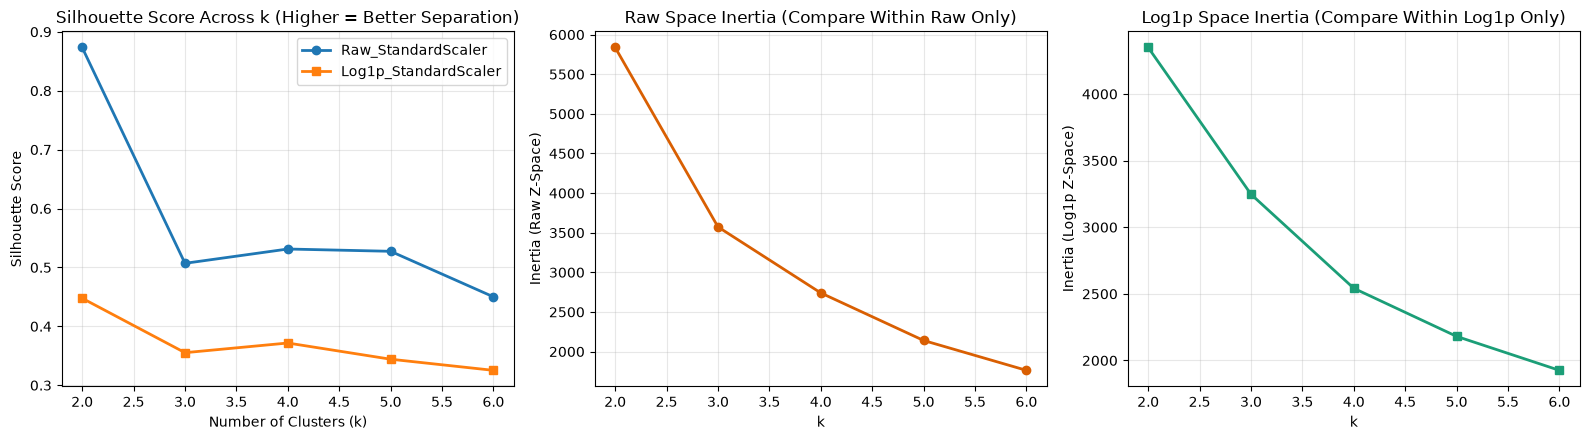

In [24]:
def get_cluster_profiles(rfm_df: pd.DataFrame, labels: np.ndarray, design_name: str) -> pd.DataFrame:
    temp = rfm_df.copy()
    temp["Cluster"] = labels
    prof = (
        temp.groupby("Cluster")
        .agg(
            Count=("CustomerID", "count"),
            Recency_Mean=("Recency", "mean"),
            Recency_Median=("Recency", "median"),
            Frequency_Mean=("Frequency", "mean"),
            Frequency_Median=("Frequency", "median"),
            Monetary_Mean=("Monetary", "mean"),
            Monetary_Median=("Monetary", "median"),
        )
        .reset_index()
    )
    prof.insert(0, "Design", design_name)
    return prof

prof_raw_k3 = get_cluster_profiles(rfm_dev, cluster_assignments[("Raw_StandardScaler", 3)], "Raw_StandardScaler_k3")
prof_log_k3 = get_cluster_profiles(rfm_dev, cluster_assignments[("Log1p_StandardScaler", 3)], "Log1p_StandardScaler_k3")
prof_log_k4 = get_cluster_profiles(rfm_dev, cluster_assignments[("Log1p_StandardScaler", 4)], "Log1p_StandardScaler_k4")

shortlisted_profiles = pd.concat([prof_raw_k3, prof_log_k3, prof_log_k4], ignore_index=True)
shortlisted_profiles.to_csv(REPORTS_DIR / "shortlisted_profiles.csv", index=False)
display(shortlisted_profiles.round(2))

# Plot Silhouette & Within-Representation Inertia curves
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for rep_name, marker in [("Raw_StandardScaler", "o"), ("Log1p_StandardScaler", "s")]:
    sub = candidate_df[candidate_df["Representation"] == rep_name]
    axes[0].plot(sub["k"], sub["Silhouette"], marker=marker, linewidth=2, label=rep_name)

axes[0].set_title("Silhouette Score Across k (Higher = Better Separation)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Separate Inertia subplots (never compare raw vs log inertia on the same scale!)
sub_raw = candidate_df[candidate_df["Representation"] == "Raw_StandardScaler"]
axes[1].plot(sub_raw["k"], sub_raw["Inertia_Within_Rep"], marker="o", color="#d95f02", linewidth=2)
axes[1].set_title("Raw Space Inertia (Compare Within Raw Only)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Inertia (Raw Z-Space)")
axes[1].grid(True, alpha=0.3)

sub_log = candidate_df[candidate_df["Representation"] == "Log1p_StandardScaler"]
axes[2].plot(sub_log["k"], sub_log["Inertia_Within_Rep"], marker="s", color="#1b9e77", linewidth=2)
axes[2].set_title("Log1p Space Inertia (Compare Within Log1p Only)")
axes[2].set_xlabel("k")
axes[2].set_ylabel("Inertia (Log1p Z-Space)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "part_c_candidate_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

# Seed Stability (ARI vs Seed 42) & Sensitivity Study (99th-Percentile Monetary Cap)

In [25]:
CHOSEN_REP = "Log1p_StandardScaler"
CHOSEN_K = 4  # Check Cell 7 output; k=4 typically gives 4 balanced actionable segments (e.g., Champions, Loyalists, At-Risk/Lapsed, Recent/Low-Spend)

# 1. Seed Stability Check (seeds 1, 10, 21, 42, 100 vs seed 42)
ref_labels = cluster_assignments[(CHOSEN_REP, CHOSEN_K)]
stability_rows = []
for seed in [1, 10, 21, 42, 100]:
    km_seed = KMeans(n_clusters=CHOSEN_K, random_state=seed, n_init=10)
    seed_labels = km_seed.fit_predict(Z_log)
    ari = adjusted_rand_score(ref_labels, seed_labels)
    stability_rows.append({"Seed": seed, "Reference_Seed": 42, "ARI": ari})

stability_df = pd.DataFrame(stability_rows)
stability_df.to_csv(REPORTS_DIR / "stability.csv", index=False)
display(stability_df)

# 2. Sensitivity Study: Retaining Extreme Spenders vs Capping Monetary at Dev 99th Percentile
cap_99 = np.percentile(X_raw["Monetary"], 99)
X_capped = X_raw.copy()
X_capped["Monetary"] = np.minimum(X_capped["Monetary"], cap_99)

Z_log_capped = StandardScaler().fit_transform(np.log1p(X_capped))
km_capped = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10)
labels_capped = km_capped.fit_predict(Z_log_capped)

sens_ari = adjusted_rand_score(ref_labels, labels_capped)
sens_sil_uncapped = silhouette_score(Z_log, ref_labels)
sens_sil_capped = silhouette_score(Z_log_capped, labels_capped)

sens_df = pd.DataFrame([
    {"Variant": "Uncapped_Monetary (Chosen)", "Cap_GBP": np.nan, "Silhouette": sens_sil_uncapped, "ARI_vs_Uncapped": 1.0},
    {"Variant": "Capped_99th_Percentile", "Cap_GBP": cap_99, "Silhouette": sens_sil_capped, "ARI_vs_Uncapped": sens_ari},
])
sens_df.to_csv(REPORTS_DIR / "sensitivity_study.csv", index=False)
display(sens_df.round(4))

,Seed,Reference_Seed,ARI
0,1,42,0.997654
1,10,42,0.980094
2,21,42,0.980094
3,42,42,1.000000
4,100,42,0.980094


,Variant,Cap_GBP,Silhouette,ARI_vs_Uncapped
0,Uncapped_Monetary (Chosen),NaN,0.3717,1.0000
1,Capped_99th_Percentile,11473.71,0.3740,0.9625


# Labelled 2D PCA Visualization (Display Only)

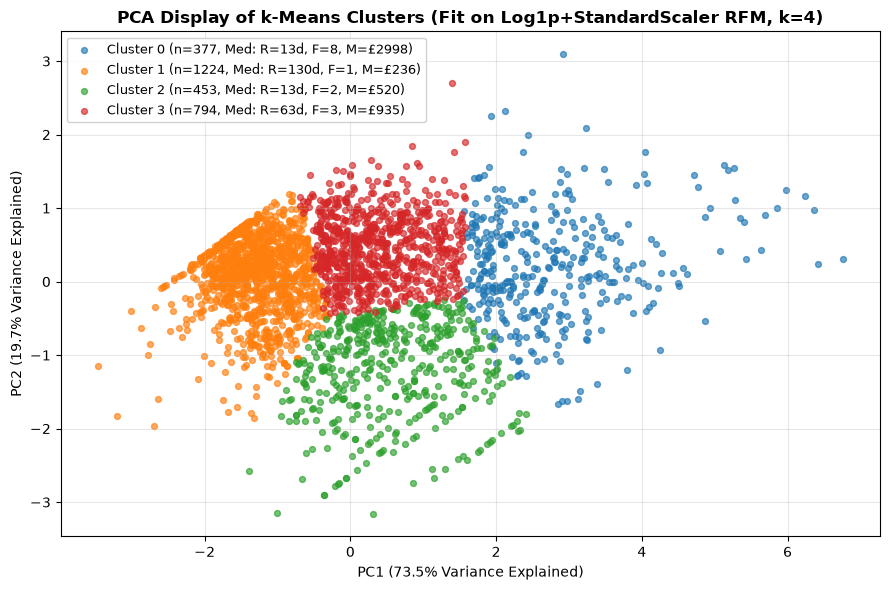

Total 2D PCA Explained Variance Ratio: 93.17% (PC1=73.52%, PC2=19.65%)


In [26]:
pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(Z_log)
evr = pca.explained_variance_ratio_

plt.figure(figsize=(9, 6))
for c_id in range(CHOSEN_K):
    mask = (ref_labels == c_id)
    med_m = rfm_dev.loc[mask, "Monetary"].median()
    med_r = rfm_dev.loc[mask, "Recency"].median()
    med_f = rfm_dev.loc[mask, "Frequency"].median()
    plt.scatter(
        Z_pca[mask, 0], Z_pca[mask, 1],
        s=18, alpha=0.65,
        label=f"Cluster {c_id} (n={mask.sum()}, Med: R={med_r:.0f}d, F={med_f:.0f}, M=£{med_m:.0f})"
    )

plt.title(f"PCA Display of k-Means Clusters (Fit on Log1p+StandardScaler RFM, k={CHOSEN_K})", fontsize=12, fontweight="bold")
plt.xlabel(f"PC1 ({evr[0]*100:.1f}% Variance Explained)")
plt.ylabel(f"PC2 ({evr[1]*100:.1f}% Variance Explained)")
plt.legend(loc="best", fontsize=9, framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part_c_pca_clusters.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Total 2D PCA Explained Variance Ratio: {evr.sum()*100:.2f}% (PC1={evr[0]*100:.2f}%, PC2={evr[1]*100:.2f}%)")

# Contact Policy Function, Baseline Function, & Out-of-Time Evaluator

In [27]:
def assign_segment_roles(rfm_df: pd.DataFrame, labels: np.ndarray) -> pd.Series:
    """
    Deterministically map arbitrary k-Means cluster IDs (0..3) to business roles
    using median profile statistics so refits remain consistent across cutoffs.
    """
    temp = rfm_df.copy()
    temp["Cluster"] = labels
    stats = temp.groupby("Cluster").agg(
        Med_R=("Recency", "median"),
        Med_F=("Frequency", "median"),
        Med_M=("Monetary", "median"),
    )
    # 1. Core Champions: highest median Monetary
    champ_id = stats["Med_M"].idxmax()
    rem = stats.drop(index=champ_id)
    # 2. Dormant / One-Time: highest median Recency among remaining
    dormant_id = rem["Med_R"].idxmax()
    rem = rem.drop(index=dormant_id)
    # 3. Recent Promising vs At-Risk Established: lower median Recency = Recent Promising
    recent_id = rem["Med_R"].idxmin()
    at_risk_id = rem["Med_R"].idxmax()
    
    role_map = {
        champ_id: "Core_Champions",
        at_risk_id: "At_Risk_Established",
        recent_id: "Recent_Promising",
        dormant_id: "Dormant_One_Time",
    }
    return pd.Series(labels).map(role_map)

def select_cluster_policy(rfm_df: pd.DataFrame, labels: np.ndarray) -> pd.DataFrame:
    B = min(200, int(np.floor(0.10 * len(rfm_df))))
    work = rfm_df.copy()
    work["Cluster"] = labels
    work["Segment_Role"] = assign_segment_roles(work, labels).values
    
    # Deterministic ranking within each segment
    work = work.sort_values(
        by=["Monetary", "Recency", "Frequency", "CustomerID"],
        ascending=[False, True, False, True]
    ).reset_index(drop=True)
    
    priority_order = ["Core_Champions", "At_Risk_Established", "Recent_Promising", "Dormant_One_Time"]
    weights = {"Core_Champions": 0.50, "At_Risk_Established": 0.25, "Recent_Promising": 0.20, "Dormant_One_Time": 0.05}
    
    # Initial floor quotas + remainder assigned to top priority
    quotas = {r: int(np.floor(B * weights[r])) for r in priority_order}
    quotas["Core_Champions"] += B - sum(quotas.values())
    
    selected_parts = []
    used_cids = set()
    unused_slots = 0
    
    for role in priority_order:
        pool = work[(work["Segment_Role"] == role) & (~work["CustomerID"].isin(used_cids))]
        target = quotas[role]
        take = pool.head(target).copy()
        take["Selection_Reason"] = f"Cluster Policy ({role}: top Monetary within segment quota)"
        selected_parts.append(take)
        used_cids.update(take["CustomerID"])
        unused_slots += max(0, target - len(take))
        
    # Redistribute any unused slots if a small cluster was exhausted
    if unused_slots > 0:
        for role in priority_order:
            if unused_slots == 0:
                break
            pool = work[(work["Segment_Role"] == role) & (~work["CustomerID"].isin(used_cids))]
            extra = pool.head(unused_slots).copy()
            extra["Selection_Reason"] = f"Cluster Policy ({role}: redistributed unused slot)"
            selected_parts.append(extra)
            used_cids.update(extra["CustomerID"])
            unused_slots -= len(extra)
            
    out = pd.concat(selected_parts, ignore_index=True)
    out.insert(0, "Rank", np.arange(1, len(out) + 1))
    assert len(out) == B and out["CustomerID"].is_unique
    return out

def select_baseline_policy(rfm_df: pd.DataFrame) -> pd.DataFrame:
    B = min(200, int(np.floor(0.10 * len(rfm_df))))
    out = (
        rfm_df.sort_values(by=["Monetary", "CustomerID"], ascending=[False, True])
        .head(B)
        .copy()
        .reset_index(drop=True)
    )
    out.insert(0, "Rank", np.arange(1, len(out) + 1))
    out["Selection_Reason"] = "Baseline (Top past Monetary GBP)"
    assert len(out) == B and out["CustomerID"].is_unique
    return out

def evaluate_out_of_time(selected_df: pd.DataFrame, cohort_rfm: pd.DataFrame, clean_txns: pd.DataFrame, start_str: str, end_str: str, policy_name: str, total_k: int = 4) -> dict:
    start_dt, end_dt = pd.Timestamp(start_str), pd.Timestamp(end_str)
    # Only transactions in [start_dt, end_dt) from customers ALREADY eligible at cutoff (no new September entrants!)
    window_txns = clean_txns[(clean_txns["InvoiceDate"] >= start_dt) & (clean_txns["InvoiceDate"] < end_dt)].copy()
    eligible_ids = set(cohort_rfm["CustomerID"])
    cohort_window = window_txns[window_txns["CustomerID"].isin(eligible_ids)]
    
    total_cohort_spend = cohort_window["LineValue"].sum()
    sel_ids = set(selected_df["CustomerID"])
    sel_window = cohort_window[cohort_window["CustomerID"].isin(sel_ids)]
    
    repeat_buyers = sel_window["CustomerID"].nunique()
    sel_spend = sel_window["LineValue"].sum()
    n_sel = len(selected_df)
    
    repeat_rate = (repeat_buyers / n_sel) if n_sel > 0 else 0.0
    spend_per_contact = (sel_spend / n_sel) if n_sel > 0 else 0.0
    spend_share = (sel_spend / total_cohort_spend) if total_cohort_spend > 0 else 0.0
    clusters_covered = selected_df["Cluster"].nunique() if "Cluster" in selected_df.columns else np.nan
    
    return {
        "Policy": policy_name,
        "Selected_Count": n_sel,
        "Contact_Cost_GBP": n_sel * 2.0,
        "Repeat_Buyers": repeat_buyers,
        "Repeat_Purchase_Rate": repeat_rate,
        "Selected_Spend_GBP": sel_spend,
        "Spend_Per_Contact_GBP": spend_per_contact,
        "Cohort_Spend_Share": spend_share,
        "Clusters_Covered": clusters_covered,
    }

# Development Comparison (Aug 2011) & Untouched Final Assessment (Sept 2011)

In [28]:
# 1. Development Stage (Cutoff 2011-08-01, Evaluate on Aug 2011)
dev_cluster_list = select_cluster_policy(rfm_dev, ref_labels)
dev_baseline_list = select_baseline_policy(rfm_dev)

dev_eval = pd.DataFrame([
    evaluate_out_of_time(dev_baseline_list, rfm_dev, df, "2011-08-01", "2011-09-01", "Dev_Baseline_TopMonetary"),
    evaluate_out_of_time(dev_cluster_list, rfm_dev, df, "2011-08-01", "2011-09-01", "Dev_Cluster_Policy_k4"),
])
dev_eval.to_csv(REPORTS_DIR / "development_comparison.csv", index=False)
print("=== DEVELOPMENT EVALUATION (AUGUST 2011) ===")
display(dev_eval.round(4))

# 2. Final Assessment Stage (Refit strictly on < 2011-09-01, Save Lists BEFORE inspecting Sept)
scaler_final = StandardScaler()
Z_final = scaler_final.fit_transform(np.log1p(rfm_final[features_cols]))
km_final = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10)
final_labels = km_final.fit_predict(Z_final)

final_cluster_list = select_cluster_policy(rfm_final, final_labels)
final_baseline_list = select_baseline_policy(rfm_final)

# Save both lists prior to computing September outcomes
final_cluster_list.to_csv(REPORTS_DIR / "final_selected_cluster_list.csv", index=False)
final_baseline_list.to_csv(REPORTS_DIR / "final_baseline_list.csv", index=False)

# Compute untouched September 2011 outcomes
final_eval = pd.DataFrame([
    evaluate_out_of_time(final_baseline_list, rfm_final, df, "2011-09-01", "2011-10-01", "Final_Baseline_TopMonetary"),
    evaluate_out_of_time(final_cluster_list, rfm_final, df, "2011-09-01", "2011-10-01", "Final_Cluster_Policy_k4"),
])
final_eval.to_csv(REPORTS_DIR / "final_outcomes.csv", index=False)
print("\n=== UNTOUCHED FINAL ASSESSMENT (SEPTEMBER 2011) ===")
display(final_eval.round(4))

print("\nSelected Customer Count per Cluster (Final):")
display(final_cluster_list.groupby(["Cluster", "Segment_Role"]).size().reset_index(name="Selected_Count"))

# Show concrete example where policies differ
only_in_cluster = set(final_cluster_list["CustomerID"]) - set(final_baseline_list["CustomerID"])
example_cid = sorted(list(only_in_cluster))[0]
print(f"\nExample Customer Selected by Cluster Policy but Missed by Baseline: CustomerID {example_cid}")
display(final_cluster_list[final_cluster_list["CustomerID"] == example_cid])

=== DEVELOPMENT EVALUATION (AUGUST 2011) ===


,Policy,Selected_Count,Contact_Cost_GBP,Repeat_Buyers,Repeat_Purchase_Rate,Selected_Spend_GBP,Spend_Per_Contact_GBP,Cohort_Spend_Share,Clusters_Covered
0,Dev_Baseline_TopMonetary,200,400.0,147,0.735,226249.94,1131.2497,0.5134,NaN
1,Dev_Cluster_Policy_k4,200,400.0,110,0.550,182682.17,913.4109,0.4146,4.0



=== UNTOUCHED FINAL ASSESSMENT (SEPTEMBER 2011) ===


,Policy,Selected_Count,Contact_Cost_GBP,Repeat_Buyers,Repeat_Purchase_Rate,Selected_Spend_GBP,Spend_Per_Contact_GBP,Cohort_Spend_Share,Clusters_Covered
0,Final_Baseline_TopMonetary,200,400.0,146,0.73,336982.52,1684.9126,0.5124,NaN
1,Final_Cluster_Policy_k4,200,400.0,118,0.59,319367.13,1596.8356,0.4856,4.0



Selected Customer Count per Cluster (Final):


,Cluster,Segment_Role,Selected_Count
0,0,Recent_Promising,40
1,1,Dormant_One_Time,10
2,2,Core_Champions,100
3,3,At_Risk_Established,50



Example Customer Selected by Cluster Policy but Missed by Baseline: CustomerID 12749


,Rank,CustomerID,Recency,Frequency,Monetary,Cluster,Segment_Role,Selection_Reason
126,127,12749,31,3,2755.23,3,At_Risk_Established,Cluster Policy (At_Risk_Established: top Monet...


# Part E — Save Workflow Bundle (joblib), Predict New Customer, & Invalid Input Checks

In [29]:
import joblib
import sklearn

bundle = {
    "scaler": scaler_final,
    "kmeans": km_final,
    "feature_order": ["Recency", "Frequency", "Monetary"],
    "feature_definitions": {
        "Recency": "Calendar days since last valid positive purchase before cutoff",
        "Frequency": "Distinct valid positive InvoiceNo count before cutoff",
        "Monetary": "Total positive GBP purchase value (Quantity * UnitPrice) before cutoff",
    },
    "transform": "np.log1p -> StandardScaler",
    "n_clusters": CHOSEN_K,
    "cutoff_date": "2011-09-01",
    "eligibility_rules": "Country == 'United Kingdom', non-null CustomerID, non-cancelled, Quantity > 0, UnitPrice > 0, InvoiceDate < 2011-09-01",
    "library_versions": {
        "python": "3.14",
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
}

BUNDLE_PATH = MODELS_DIR / "rfm_segmentation_bundle.joblib"
joblib.dump(bundle, BUNDLE_PATH)

# 1. Reload and verify exact match on all final customers
reloaded = joblib.load(BUNDLE_PATH)

def predict_customer_cluster(new_rfm_df: pd.DataFrame, model_bundle: dict) -> np.ndarray:
    expected_cols = model_bundle["feature_order"]
    if list(new_rfm_df.columns) != expected_cols:
        raise ValueError(f"Schema mismatch! Expected exact columns {expected_cols}, got {list(new_rfm_df.columns)}")
    if new_rfm_df.isna().any().any():
        raise ValueError("Missing/NaN values detected in RFM input!")
    if (new_rfm_df["Recency"] < 0).any() or (new_rfm_df["Frequency"] < 1).any() or (new_rfm_df["Monetary"] <= 0).any():
        raise ValueError("Invalid RFM range: Recency must be >= 0, Frequency >= 1, Monetary > 0.")
    
    Z_new = model_bundle["scaler"].transform(np.log1p(new_rfm_df[expected_cols]))
    return model_bundle["kmeans"].predict(Z_new)

reloaded_preds = predict_customer_cluster(rfm_final[features_cols], reloaded)
assert np.array_equal(final_labels, reloaded_preds), "Reloaded model predictions do not match!"
print("VERIFIED: Saved & reloaded joblib bundle produces 100% identical cluster assignments.")

# 2. Assign a newly prepared customer RFM row without retraining
sample_new_customer = pd.DataFrame([{"Recency": 14, "Frequency": 5, "Monetary": 1450.00}])
assigned_cluster = predict_customer_cluster(sample_new_customer, reloaded)[0]
print(f"New Customer (R=14d, F=5, M=£1450.00) assigned to Cluster: {assigned_cluster} (without retraining)")

# 3. Demonstrate clear validation failures for at least two invalid inputs
for test_name, bad_df in [
    ("Invalid Input 1 (Missing 'Monetary' column)", pd.DataFrame([{"Recency": 10, "Frequency": 2}])),
    ("Invalid Input 2 (Negative Recency)", pd.DataFrame([{"Recency": -5, "Frequency": 3, "Monetary": 300.0}])),
]:
    try:
        predict_customer_cluster(bad_df, reloaded)
    except ValueError as e:
        print(f"PASS — {test_name} caught cleanly: {e}")

VERIFIED: Saved & reloaded joblib bundle produces 100% identical cluster assignments.
New Customer (R=14d, F=5, M=£1450.00) assigned to Cluster: 2 (without retraining)
PASS — Invalid Input 1 (Missing 'Monetary' column) caught cleanly: Schema mismatch! Expected exact columns ['Recency', 'Frequency', 'Monetary'], got ['Recency', 'Frequency']
PASS — Invalid Input 2 (Negative Recency) caught cleanly: Invalid RFM range: Recency must be >= 0, Frequency >= 1, Monetary > 0.
